# Ирисы Фишера
Выборка взята отсюда: https://archive.ics.uci.edu/ml/datasets/iris

In [1]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

dataset = pd.read_csv('iris/iris.data',
                      header=None,
                      names=['длина чашелистика', 'ширина чашелистика',
                             'длина лепестка', 'ширина лепестка', 'класс'])
dataset.sample(5, random_state=0)

print('Размер выборки составляет l={} объектов.'.format(len(dataset)))

Размер выборки составляет l=150 объектов.


    ## Множество объектов
    В данной задаче множество объектов описывается 
    признаками:
    ```text
    1) Длина чашелистика
    2) Ширина чашелистика
    3) Длина лепестка
    4) Ширина лепестка
    ```
    ## Множество ответов
    В данной задаче множество ответов состоит из трех элементов:

    ```text
    1) Iris-virginica
    2) Iris-versicolor
    3) Iris-setosa
    ```
Задача машинного обучения
В нашем случае, так как мощность множества |y| = 3 << l = 150 , получаем задачу классификации на M = 3 класса.

## Анализ данных

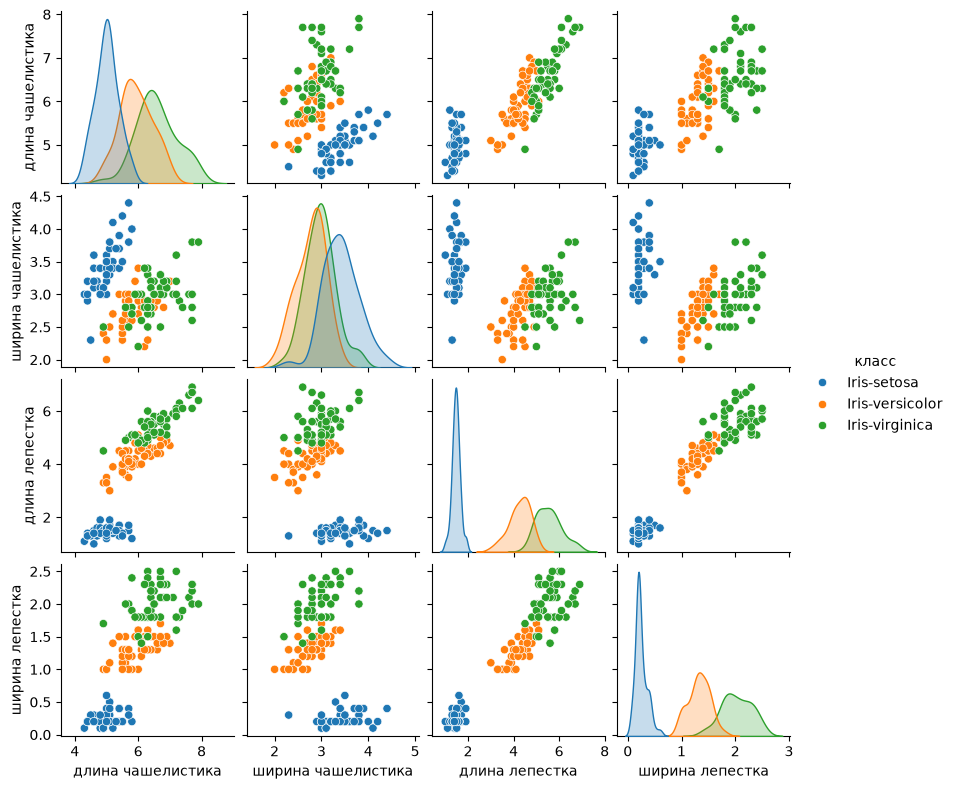

In [2]:
sns.pairplot(dataset, hue='класс', height=2)
plt.show()

## Построение модели

Так как класс Iris-setosa легко легко отделяется от других цветов, уберем его из выборки и перейдем к задаче бинарной классификации.

In [5]:
binary_dataset = dataset[dataset['класс'] != 'Iris-setosa'].copy()

binary_dataset['класс'] = binary_dataset['класс'].map({
    'Iris-versicolor': -1,
    'Iris-virginica': 1
})

In [7]:
X = binary_dataset.iloc[:, binary_dataset.columns != 'класс'].values
y = binary_dataset.iloc[:, binary_dataset.columns == 'класс'].values.reshape(-1)
X = np.array(np.hstack([X, np.ones([len(X), 1])]), dtype=np.float64)
y = np.array(y, dtype=np.int64)

model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X, y)

model.coef_

array([[-3.94857799e-01, -5.12236925e-01,  2.93150207e+00,
         2.41616121e+00, -1.17463494e-03]])

## Переход от бинарной классификации к многоклассовой

Рассмотрим вариант перехода, который называется "Один против всех (One VS All)". Для простоты визуализации рассмотрим пример на синтетических данных.

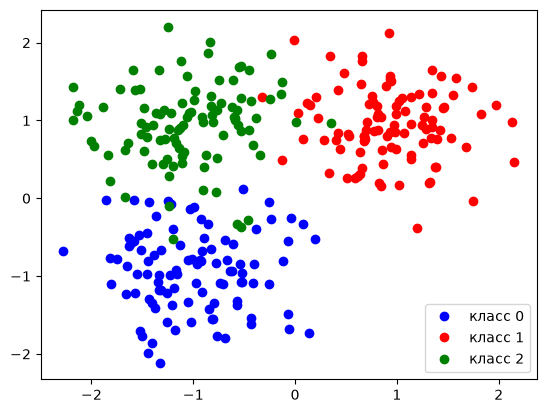

In [8]:
np.random.seed(0)
l = 100
n = 2
X1 = np.array([[-1,-1]]) + 0.5*np.random.randn(l, n)
X2 = np.array([[1,1]]) + 0.5*np.random.randn(l, n)
X3 = np.array([[-1,1]]) + 0.5*np.random.randn(l, n)

X = np.vstack([X1, X2, X3])
y = np.hstack([[0]*l, [1]*l, [2]*l])

cols = ['blue', 'red', 'green']

# построение точек
for k in np.unique(y):
    plt.plot(X[y==k,0], X[y==k,1], 'o', label='класс {}'.format(k), color=cols[k])

plt.legend(loc='best')
plt.show()

Данный метод основан на том, что для классификации на M > 2 классов нужно построить M линейных классификаторов, 
которые классифицируют k-й класс против всех остальных классов.

Построим M = 3 классификатора, которые отделяют каждый класс от двух остальных

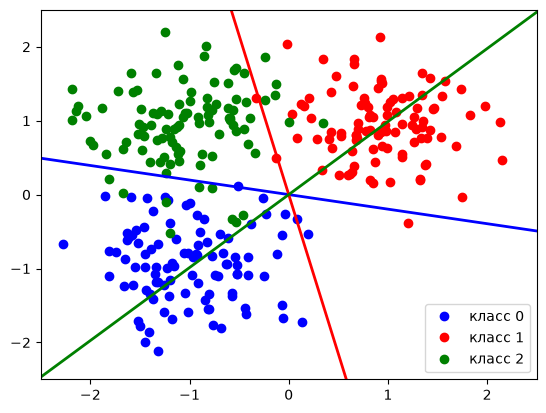

In [9]:
models = []
model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X, np.array(y==0, dtype=np.int64))
models.append(model)

model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X, np.array(y==1, dtype=np.int64))
models.append(model)

model = LogisticRegression(random_state=0, max_iter=2000)
_ = model.fit(X, np.array(y==2, dtype=np.int64))
models.append(model)

cols = ['blue', 'red', 'green']
plt.xlim((-2.5, 2.5))
plt.ylim((-2.5, 2.5))

# построение точек
for k in np.unique(y):
    plt.plot(X[y==k,0], X[y==k,1], 'o', label='класс {}'.format(k), color=cols[k])

# построение прямой, перпендикулярной к разделяющей
for k in np.unique(y):
    # нормальный вектор к прямой
    x2, y2 = -models[k].coef_[0][1]/models[k].coef_[0][0], 1

    polynomial = np.poly1d(np.polyfit([0, x2], [0, y2], 1))
    x_axis = np.linspace(-10, 10)
    y_axis = polynomial(x_axis)
    plt.plot(x_axis, y_axis, linewidth=2, color=cols[k])

plt.legend(loc='best')
plt.show()

По данному рисунку возникает сразу несколько вопросов:

1. Как видно на рисунке, в класс зеленых точек попадает много зеленых и много красных точек. Такое случилось потому, что мы считали просто скалярное произведение, без добавления аддитивной константы, которая, грубо говоря, приближает разделяющую прямую к истинным точкам или отдаляет.
2. Есть точки, которые попадают сразу в несколько областей. 

Один из вариантов следующий:

1. Всего плоскость разделена на 6 областей.
2. Считаем, в какую область попала точка, и получаем нужный класс.

## Методы анализа качества

In [10]:
scores = np.zeros([3,3])
for k in range(3):
    pred = np.argmax(np.vstack([models[i].predict_proba(X[y==k])[:, 1] for i in range(3)]).T, axis=1)
    for i in range(3):
        scores[i, k] = sum(pred == i)

print(scores)

[[98.  0.  6.]
 [ 0. 98.  2.]
 [ 2.  2. 92.]]


Результаты данной таблицы показывают такой же результат, как и картинка. Хуже всего от других отделим второй класс.

## Пример переобучения на синтеческих данных

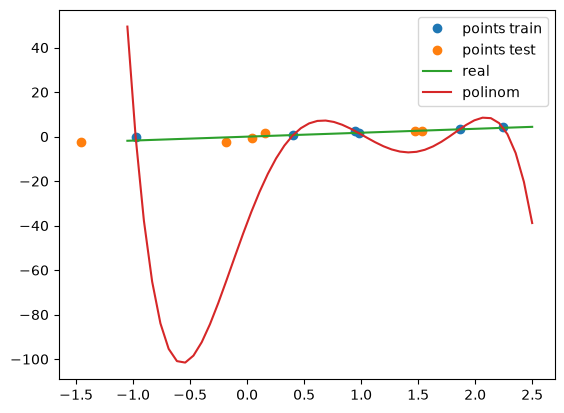

In [11]:
np.random.seed(0)
l = 6
n = 1
w = np.random.randn(n)
X_tr = np.random.randn(l, n)
y_tr = X_tr@w + np.random.randn(l)

X_vl = np.random.randn(l, n)
y_vl = X_vl@w + np.random.randn(l)

X_ts = np.random.randn(l, n)
y_ts = X_ts@w + np.random.randn(l)

x_begin = -1.05
x_end = 2.5
X_polinom = np.hstack([X_tr**0, X_tr**1, X_tr**2, X_tr**3, X_tr**4, X_tr**5])
w_polinom = np.linalg.inv(X_polinom.T@X_polinom)@X_polinom.T@y_tr
y_polinom = list(map(lambda x: np.array([x**0, x**1, x**2, x**3, x**4, x**5])@w_polinom, 
                     np.linspace(x_begin, x_end)))

plt.plot(X_tr, y_tr, 'o', label = 'points train')
plt.plot(X_ts, y_ts, 'o', label = 'points test')
plt.plot(np.linspace(x_begin, x_end), w*np.linspace(x_begin, x_end), '-', label = 'real')
plt.plot(np.linspace(x_begin, x_end), y_polinom, '-', label = 'polinom')

plt.legend(loc='best')
plt.show()